In [100]:
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

In [101]:
# ============================================================
# 1. Reproducibility
# ============================================================

torch.manual_seed(42)


In [102]:
# ============================================================
# 2. Generate training and validation data
# ============================================================

N = 1000

# Randomly sample x from [-100, 100]
x = -100 + 200 * torch.rand(N, 1)

# Target: sin(x)
y = torch.sin(x)

# Shuffle and split 80/20
indices = torch.randperm(N)
train_size = int(0.8 * N)

train_idx = indices[:train_size]
val_idx = indices[train_size:]

x_train = x[train_idx]
y_train = y[train_idx]

x_val = x[val_idx]
y_val = y[val_idx]



In [103]:
# ============================================================
# 3. Normalize the input
# ============================================================

# Transform x from [-100, 100] approximately to [-1, 1].
x_train_norm = x_train / 100
x_val_norm = x_val / 100


In [104]:
# ============================================================
# 4. Create Dataset and DataLoader objects
# ============================================================

# TensorDataset pairs each input with its corresponding target.
train_dataset = TensorDataset(x_train_norm, y_train)
val_dataset = TensorDataset(x_val_norm, y_val)

batch_size = 64

# Shuffle training examples each epoch so batches differ.
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

# Validation does not need shuffling.
val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)



In [105]:
# ============================================================
# 5. Define the neural network
# ============================================================

class SineNet(nn.Module):

    def __init__(self, hidden_layer_width=128):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(1, hidden_layer_width),
            nn.Tanh(),

            nn.Linear(hidden_layer_width, hidden_layer_width),
            nn.Tanh(),

            nn.Linear(hidden_layer_width, 1)
        )

    def forward(self, x):
        return self.network(x)


In [106]:

model = SineNet()
print(model)


SineNet(
  (network): Sequential(
    (0): Linear(in_features=1, out_features=128, bias=True)
    (1): Tanh()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): Tanh()
    (4): Linear(in_features=128, out_features=1, bias=True)
  )
)


In [107]:
# ============================================================
# 6. Loss function and optimizer
# ============================================================

loss_fn = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)


In [108]:
# ============================================================
# 7. Training and validation loops
# ============================================================

# The original full-batch version performed one optimizer update
# per epoch. With batch_size=64, there are 13 updates per epoch
# for 800 training examples. Start with 2,000 epochs rather than
# 20,000 to keep the total number of updates in a similar range.
epochs = 2_000

train_losses = []
val_losses = []

for epoch in range(epochs):

    # ----------------------------------------
    # Training
    # ----------------------------------------

    model.train()

    # Accumulate loss weighted by the number of examples in each
    # batch, so the epoch loss is an example-level average.
    total_train_loss = 0.0
    train_examples_seen = 0

    for batch_x, batch_y in train_loader:

        # Forward pass for this mini-batch
        predictions = model(batch_x)

        # Calculate the batch's mean squared error
        loss = loss_fn(predictions, batch_y)

        # Clear gradients from the previous mini-batch
        optimizer.zero_grad()

        # Backpropagation
        loss.backward()

        # Update parameters
        optimizer.step()

        batch_examples = batch_x.size(0)
        total_train_loss += loss.item() * batch_examples
        train_examples_seen += batch_examples

    epoch_train_loss = total_train_loss / train_examples_seen

    # ----------------------------------------
    # Validation
    # ----------------------------------------

    model.eval()

    total_val_loss = 0.0
    val_examples_seen = 0

    with torch.no_grad():
        for batch_x, batch_y in val_loader:
            val_predictions = model(batch_x)
            val_loss = loss_fn(val_predictions, batch_y)

            batch_examples = batch_x.size(0)
            total_val_loss += val_loss.item() * batch_examples
            val_examples_seen += batch_examples

    epoch_val_loss = total_val_loss / val_examples_seen

    train_losses.append(epoch_train_loss)
    val_losses.append(epoch_val_loss)

    # ----------------------------------------
    # Print progress
    # ----------------------------------------

    if (epoch + 1) % 100 == 0:
        print(
            f"Epoch {epoch + 1:5d} | "
            f"Train Loss: {epoch_train_loss:.6f} | "
            f"Val Loss: {epoch_val_loss:.6f}"
        )


Epoch   100 | Train Loss: 0.514890 | Val Loss: 0.508657
Epoch   200 | Train Loss: 0.513188 | Val Loss: 0.510441
Epoch   300 | Train Loss: 0.510422 | Val Loss: 0.504939
Epoch   400 | Train Loss: 0.508996 | Val Loss: 0.504149
Epoch   500 | Train Loss: 0.507462 | Val Loss: 0.503407
Epoch   600 | Train Loss: 0.505342 | Val Loss: 0.502090
Epoch   700 | Train Loss: 0.503576 | Val Loss: 0.498770
Epoch   800 | Train Loss: 0.502838 | Val Loss: 0.498468
Epoch   900 | Train Loss: 0.501677 | Val Loss: 0.496775
Epoch  1000 | Train Loss: 0.502014 | Val Loss: 0.497222
Epoch  1100 | Train Loss: 0.500876 | Val Loss: 0.496416
Epoch  1200 | Train Loss: 0.499993 | Val Loss: 0.496751
Epoch  1300 | Train Loss: 0.499544 | Val Loss: 0.496914
Epoch  1400 | Train Loss: 0.498472 | Val Loss: 0.495426
Epoch  1500 | Train Loss: 0.498892 | Val Loss: 0.494040
Epoch  1600 | Train Loss: 0.498020 | Val Loss: 0.496473
Epoch  1700 | Train Loss: 0.496937 | Val Loss: 0.493857
Epoch  1800 | Train Loss: 0.496647 | Val Loss: 0

In [109]:
# ============================================================
# 8. Create interpolation test data
# ============================================================

x_test_inside = torch.linspace(
    -100,
    100,
    1000
).reshape(-1, 1)

y_test_inside = torch.sin(x_test_inside)
x_test_inside_norm = x_test_inside / 100



In [110]:
# ============================================================
# 9. Create extrapolation test data
# ============================================================

# Preserving the actual range in the original script: [-150, 150].
# Change these endpoints to -1000 and 1000 if you want the wider
# extrapolation experiment described in the original comments.
x_test_outside = torch.linspace(
    -150,
    150,
    1000
).reshape(-1, 1)

y_test_outside = torch.sin(x_test_outside)
x_test_outside_norm = x_test_outside / 100



In [111]:
# ============================================================
# 10. Evaluate the model
# ============================================================

model.eval()

with torch.no_grad():
    pred_inside = model(x_test_inside_norm)
    pred_outside = model(x_test_outside_norm)

    inside_loss = loss_fn(pred_inside, y_test_inside)
    outside_loss = loss_fn(pred_outside, y_test_outside)

print()
print("Evaluation")
print("-----------------------------")
print(f"Interpolation MSE: {inside_loss.item():.6f}")
print(f"Extrapolation MSE: {outside_loss.item():.6f}")




Evaluation
-----------------------------
Interpolation MSE: 0.498121
Extrapolation MSE: 0.956878


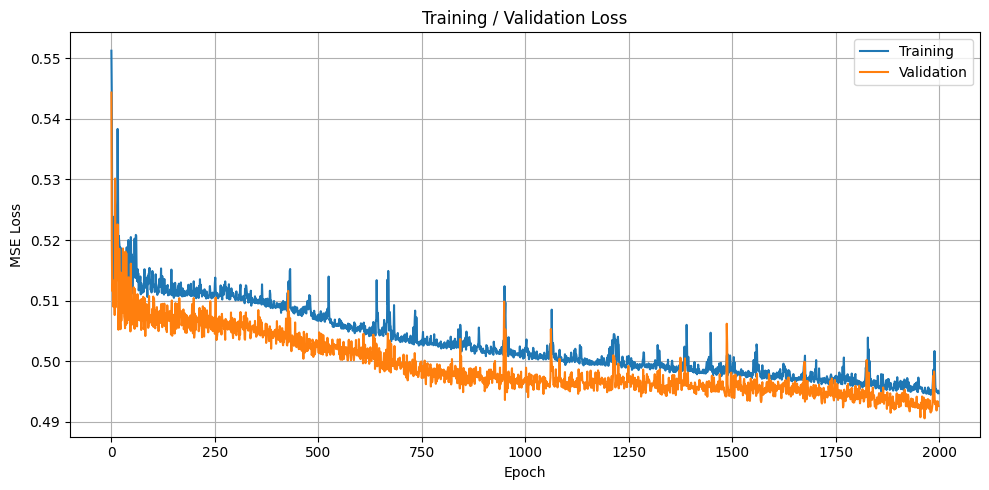

In [112]:
# ============================================================
# 11. Plot training and validation loss
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(train_losses, label="Training")
plt.plot(val_losses, label="Validation")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training / Validation Loss")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


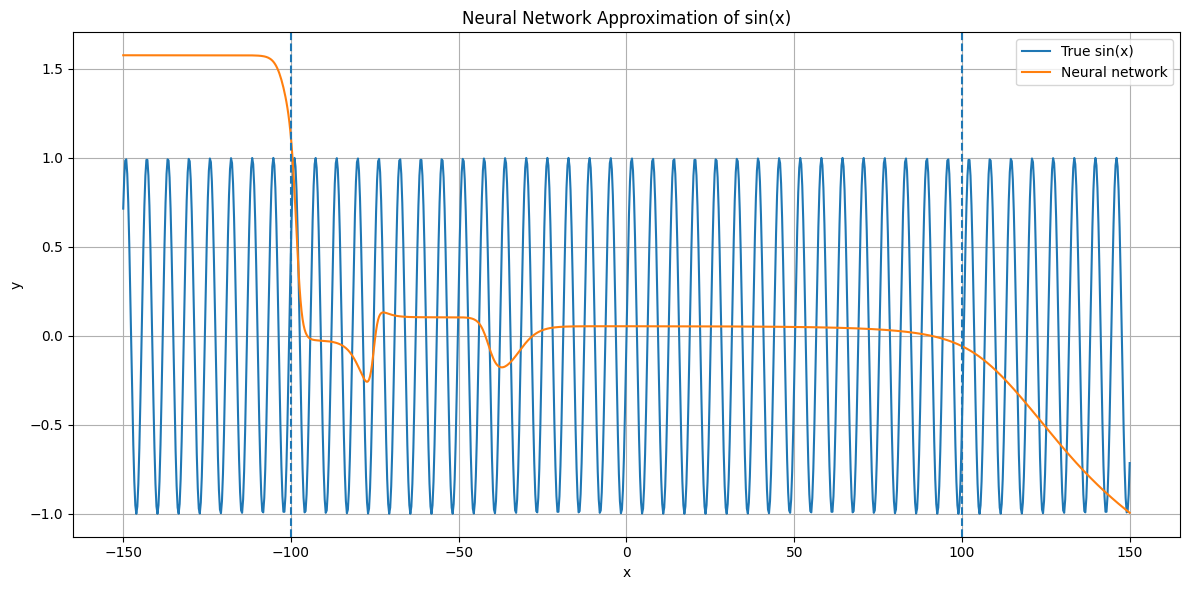

In [113]:
# ============================================================
# 12. Plot learned sine function
# ============================================================

plt.figure(figsize=(12, 6))

plt.plot(
    x_test_outside.numpy(),
    y_test_outside.numpy(),
    label="True sin(x)"
)

plt.plot(
    x_test_outside.numpy(),
    pred_outside.numpy(),
    label="Neural network"
)

plt.axvline(-100, linestyle="--")
plt.axvline(100, linestyle="--")

plt.xlabel("x")
plt.ylabel("y")
plt.title("Neural Network Approximation of sin(x)")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
